# 01 小兔鲜儿 - 项目起步


本篇是“微信小程序实战”中 **uni-app 小兔鲜儿小程序第 1 天**，根据配套资料中的 `rabbit-shop/01-项目起步.md` 整理。项目使用 uni-app、Vue 3、TypeScript 和 Pinia，先把组件、状态和请求等基础能力准备好，再进入页面业务。

本天顺序：项目架构 → 拉取模板 → 引入 uni-ui → Pinia 持久化 → 请求拦截器与 Promise 封装 → 代码规范与 Git 工作流。

资料来自[课程网盘](https://pan.baidu.com/s/1uhQQvqs9ESRvhEvgzgSUWQ?pwd=9988)，提取码 `9988`，目录为“2. uniapp小兔鲜儿小程序 / uniapp小程序-配套资料 / 02-笔记.rar”。文中的图片直接内嵌在本笔记中。


## 效果预览

原资料提供微信小程序、H5 和 Android 三端的体验入口，可先观察商城整体效果。它们用于认识最终项目；第 1 天先完成项目基础配置。

**微信小程序端**：使用微信扫描下方二维码。

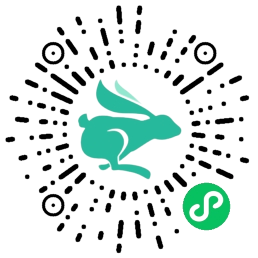


**H5 端**：[浏览器体验地址](https://megasu.gitee.io/uniapp-shop-vue3-ts/)，也可扫描下方二维码。

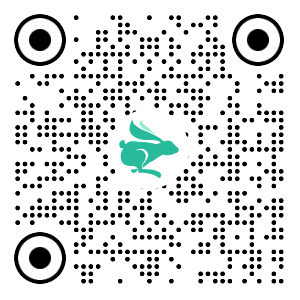


**Android App 端**：[原资料中的安装包地址](https://gitee.com/Megasu/uniapp-shop-vue3-ts/releases/download/v1.0.0/heima-shop.apk)，也可扫描下方二维码。

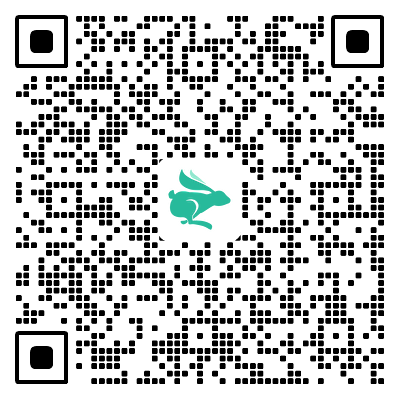


## 资料说明

| 资料 | 用途 |
| --- | --- |
| [视频课程](https://www.bilibili.com/video/BV1Bp4y1379L/) | 对照课堂操作和讲解 |
| [接口文档](https://www.apifox.cn/apidoc/shared-0e6ee326-d646-41bd-9214-29dbf47648fa/) | 查询请求路径、参数和返回结构 |
| [在线笔记](https://megasu.gitee.io/uni-app-shop-note/) | 查阅原课讲义 |
| [项目源码](https://gitee.com/Megasu/uniapp-shop-vue3-ts/) | 对照项目实现 |

以上是配套笔记列出的资料入口。起步时拉取下文的**项目模板**，模板与完整项目源码的用途不同。


## 项目架构

架构图从下到上分为三层：

| 层次 | 课程中的内容 | 作用 |
| --- | --- | --- |
| 底层框架 | uni-app、Vue.js、多平台支持、插件市场 | 提供页面开发和平台能力 |
| 业务模块 | 首页、商品详情、规格选择、登录、购物车、地址、订单与支付 | 实现商城功能 |
| 解决方案 | 请求封装、持久化存储、组件封装、下拉刷新、图片上传等 | 把重复能力整理为可复用的实现 |

第 1 天关注组件库、会员状态、持久化存储和请求封装。这些能力会被后面的业务模块反复使用。

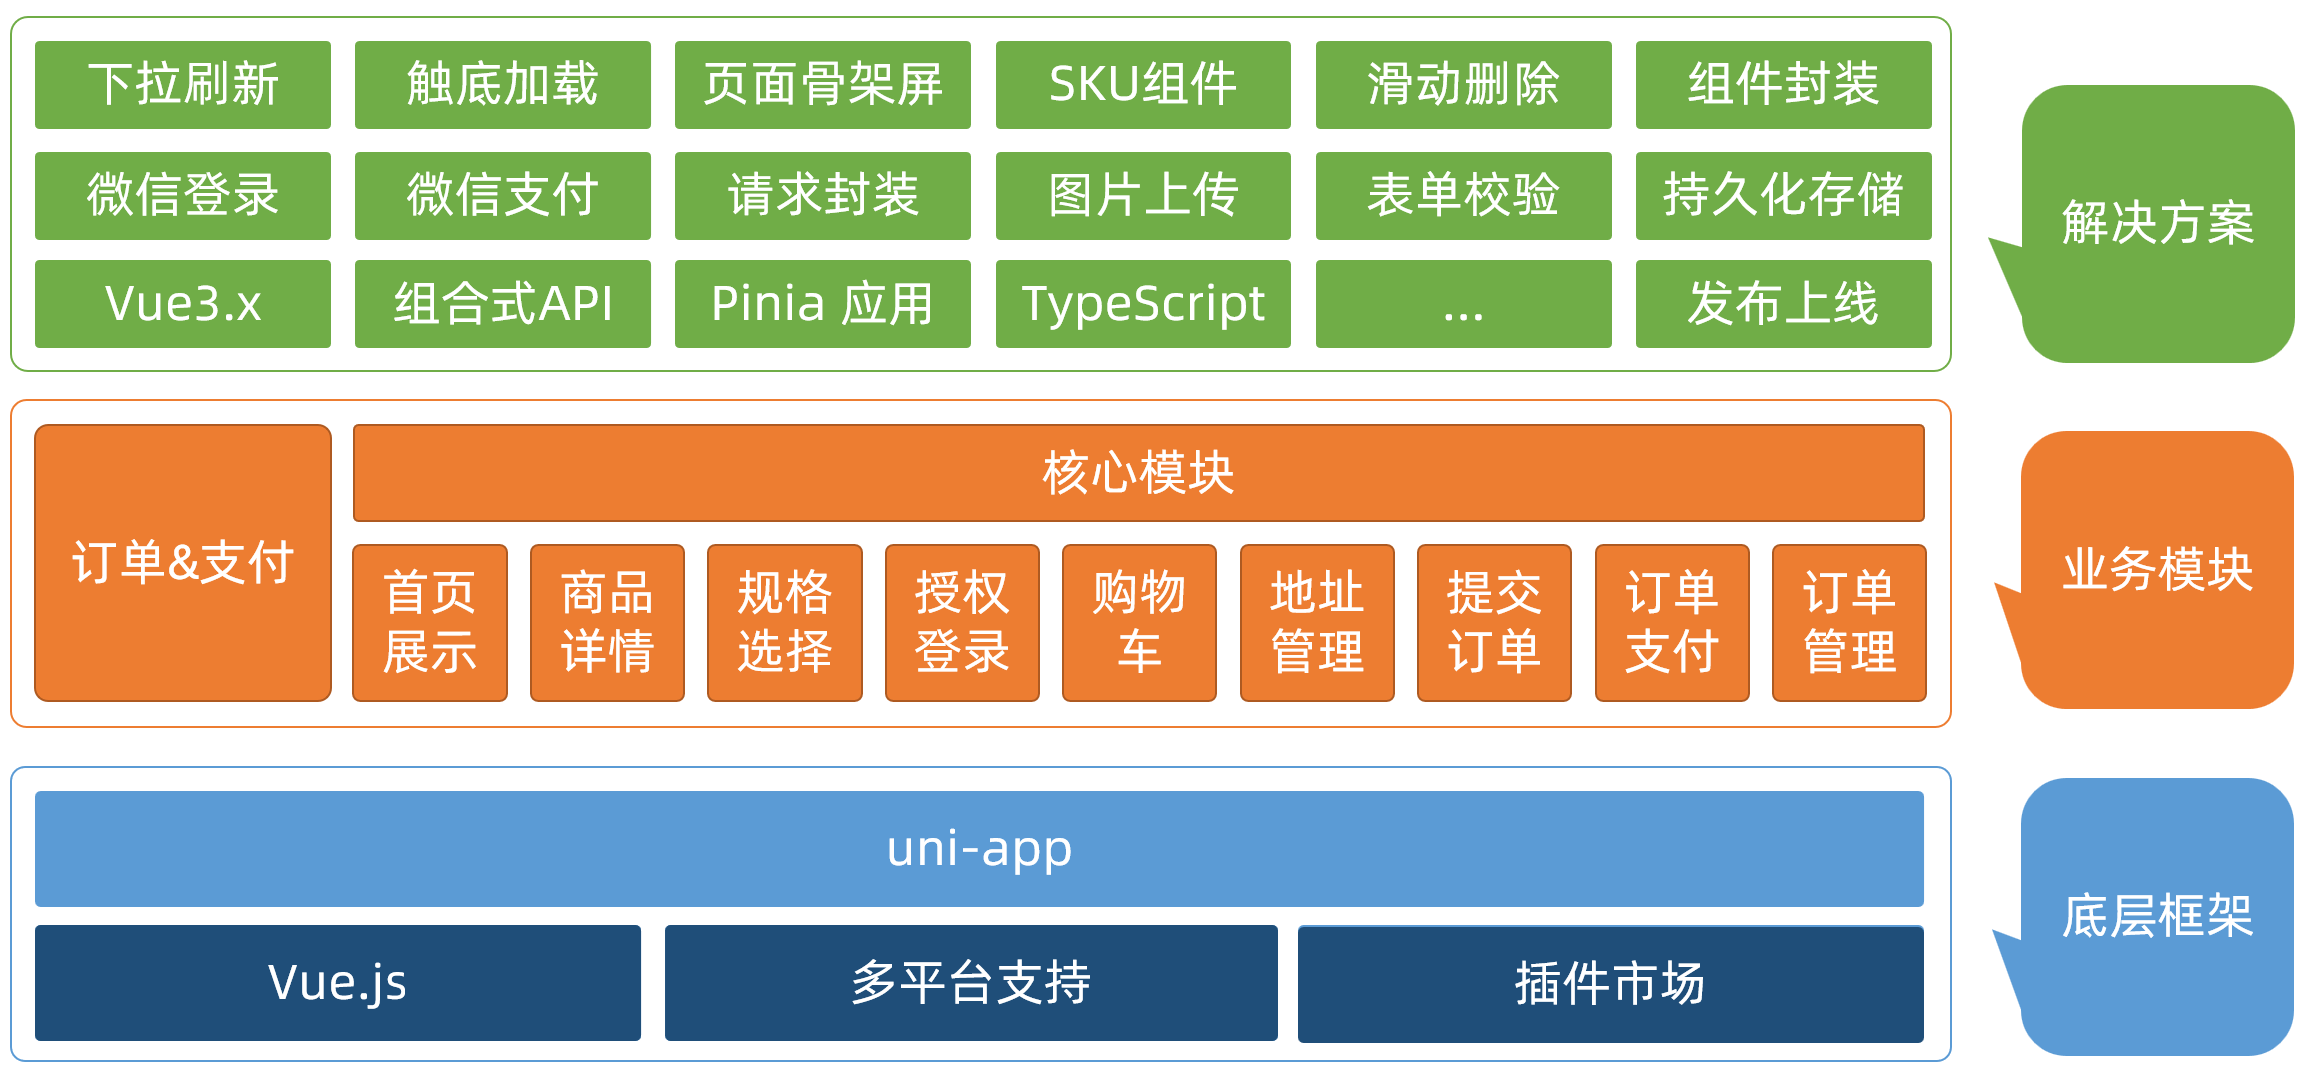


## 拉取项目模板代码

模板已经包含目录结构、项目素材和代码风格。先使用课程模板，可以把学习重点放在业务实现上。

在准备存放项目的目录执行：


```bash
git clone http://git.itcast.cn/heimaqianduan/erabbit-uni-app-vue3-ts.git heima-shop
```

命令会把项目放进 `heima-shop` 文件夹。之后安装依赖等项目命令都在该项目根目录执行。

> **原课注意事项**：小程序真机预览需要在 `manifest.json` 中填写微信小程序的 `appid`。填写自己创建的小程序 AppID。

本天主要涉及的文件：

| 文件 | 本天用途 |
| --- | --- |
| `src/pages.json` | 配置 uni-ui 的 easycom 自动导入 |
| `tsconfig.json` | 配置 API、组件的类型声明 |
| `src/stores/modules/member.ts` | 定义会员信息和持久化方式 |
| `src/stores/index.ts` | 注册 Pinia 持久化插件，统一导出 Store |
| `src/main.ts` | 把 Pinia 安装到应用 |
| `src/utils/http.ts` | 注册拦截器、导出请求函数 |
| `.eslintrc.cjs`、`package.json` | 代码检查、格式与执行脚本 |
| `.husky/pre-commit` | 提交前执行暂存文件检查 |

表中的 `src/` 是项目源码目录；根目录下的 TypeScript、依赖和工具配置不放进 `src/`。


## 引入 uni-ui 组件库

uni-ui 提供符合 uni-app 使用方式的界面组件。接入分为两件事：让运行时能找到组件，让 TypeScript 和编辑器能识别组件类型。

### 安装与自动导入

在项目根目录安装 [uni-ui](https://uniapp.dcloud.net.cn/component/uniui/quickstart.html#npm安装)：


```bash
pnpm i @dcloudio/uni-ui
```

在 `src/pages.json` 中合并 `easycom` 配置，保留模板现有的页面列表和其他配置：


```jsonc
// pages.json
{
  // 组件自动导入
  "easycom": {
    "autoscan": true,
    "custom": {
      // uni-ui 规则如下配置
      "^uni-(.*)": "@dcloudio/uni-ui/lib/uni-$1/uni-$1.vue"
    }
  },
  "pages": [
    // …省略
  ]
}
```

`autoscan` 开启组件自动扫描；`custom` 为第三方组件指定查找规则。`^uni-(.*)` 匹配以 `uni-` 开头的标签，`$1` 是括号捕获的组件名。例如 `uni-icons` 会对应：

`@dcloudio/uni-ui/lib/uni-icons/uni-icons.vue`

配置完成后，页面里使用符合规则的组件标签即可按需加载。


### 安装与配置类型声明

安装组件类型包：


```bash
pnpm i -D @uni-helper/uni-ui-types
```

在项目根目录的 `tsconfig.json` 中合并类型配置：


```jsonc
// tsconfig.json
{
  "compilerOptions": {
    // ...
    "types": [
      "@dcloudio/types", // uni-app API 类型
      "miniprogram-api-typings", // 原生微信小程序类型
      "@uni-helper/uni-app-types", // uni-app 组件类型
      "@uni-helper/uni-ui-types" // uni-ui 组件类型
    ]
  },
  // vue 编译器类型，校验标签类型
  "vueCompilerOptions": {
    "nativeTags": ["block", "component", "template", "slot"]
  }
}
```

| 类型包或配置 | 作用 |
| --- | --- |
| `@dcloudio/types` | uni-app API 的类型 |
| `miniprogram-api-typings` | 微信小程序原生 API 的类型 |
| `@uni-helper/uni-app-types` | uni-app 内置组件的类型 |
| `@uni-helper/uni-ui-types` | uni-ui 组件的类型 |
| `vueCompilerOptions.nativeTags` | 告诉 Vue 类型检查器哪些是原生标签 |

`easycom` 解决“运行时如何加载组件”，类型声明解决“开发时如何提示与检查”。只安装类型包不会让页面自动找到组件。

本节带注释和省略标记的配置使用 `jsonc` 代码围栏。它们展示的是需要合并的部分，`// …省略` 对应的现有配置应保留。


## 小程序端 Pinia 持久化

Pinia 的用法与 Vue 3 项目相同。这里需要适配的是持久化插件：插件默认使用浏览器的 `localStorage`，小程序端没有这个浏览器 API。

**持久化**就是把 Store 的数据保存到本地存储，并在下次启动时恢复。会员信息属于需要保存的数据。

### 安装与注册插件

在项目根目录安装 [pinia-plugin-persistedstate](https://prazdevs.github.io/pinia-plugin-persistedstate/zh/guide/config.html#storage)：


```bash
pnpm i pinia-plugin-persistedstate
```

在 `src/stores/index.ts` 创建 Pinia 实例并注册插件：


```typescript
import { createPinia } from 'pinia'
import persist from 'pinia-plugin-persistedstate'

// 创建 pinia 实例
const pinia = createPinia()
// 使用持久化存储插件
pinia.use(persist)

// 默认导出，给 main.ts 使用
export default pinia

// 模块统一导出
export * from './modules/member'
```

再在 `src/main.ts` 把同一个 Pinia 实例安装到应用：


```typescript
import { createSSRApp } from 'vue'
import pinia from './stores'

import App from './App.vue'
export function createApp() {
  const app = createSSRApp(App)

  app.use(pinia)
  return {
    app,
  }
}
```

顺序是：创建 Pinia → 注册持久化插件 → `app.use(pinia)`。仅安装依赖，还没有完成应用接入。

`export * from './modules/member'` 把会员 Store 统一从 `stores` 模块导出，其他文件就能从这个入口引入 `useMemberStore`。


### 定义会员 Store，并适配多端存储

原课先演示 `persist: true`，再替换它的 `storage`。默认存储与多端存储的对应关系如下：

| 操作 | 浏览器 API | uni-app 多端 API |
| --- | --- | --- |
| 保存 | `localStorage.setItem(key, value)` | `uni.setStorageSync(key, value)` |
| 读取 | `localStorage.getItem(key)` | `uni.getStorageSync(key)` |

插件调用 `storage.setItem` 和 `storage.getItem` 时，转而使用 uni-app 的同步存储 API，解决小程序端的兼容问题。

下面把原课“会员 Store”和“多端兼容”两段代码合并为 `src/stores/modules/member.ts` 的完整示例：


```typescript
import { defineStore } from 'pinia'
import { ref } from 'vue'

// 定义 Store
export const useMemberStore = defineStore(
  'member',
  () => {
    // 会员信息
    const profile = ref<any>()

    // 保存会员信息，登录时使用
    const setProfile = (val: any) => {
      profile.value = val
    }

    // 清理会员信息，退出时使用
    const clearProfile = () => {
      profile.value = undefined
    }

    // 记得 return
    return {
      profile,
      setProfile,
      clearProfile,
    }
  },
  // 配置兼容多端的持久化存储
  {
    persist: {
      storage: {
        setItem(key, value) {
          uni.setStorageSync(key, value)
        },
        getItem(key) {
          return uni.getStorageSync(key)
        },
      },
    },
  },
)
```

| 成员 | 作用 |
| --- | --- |
| `profile` | 会员信息；后续请求会读取其中的 `token` |
| `setProfile` | 登录时更新会员信息 |
| `clearProfile` | 退出或登录失效时清理会员信息 |
| `persist.storage` | 指定跨平台的保存、读取方式 |

Setup Store 内部的 `profile` 是 `ref`，所以更新时写 `profile.value`；返回它之后，从 Store 实例读取时 Pinia 会自动解包，可以写 `memberStore.profile?.token`。

代码沿用本天讲义中的 `any` 占位类型。持久化插件负责数据序列化，`storage` 的两个方法负责把插件传来的数据写入、读出。清理信息时通过 Store 的 `clearProfile()` 更新状态，持久化插件会随之同步。

**跟做检查**：在开发者工具中调用 `setProfile` 后观察本地存储，重新启动确认会员状态恢复，再调用 `clearProfile` 确认内存与存储中的会员状态一起清空。


## uni.request 请求封装

页面请求会反复需要基础地址、超时、请求头和错误处理。原课分两步集中这些逻辑：

1. 通过 `uni.addInterceptor` 在请求发出前修改请求选项。
2. 用 `http<T>` 把回调形式的 `uni.request` 包装成 Promise，并统一处理响应。

拦截器负责“怎么发出”，请求函数负责“怎么处理结果”。[拦截器文档](https://uniapp.dcloud.net.cn/api/interceptor.html)和[本项目接口说明](https://www.apifox.cn/apidoc/shared-0e6ee326-d646-41bd-9214-29dbf47648fa/doc-1521513)可与代码对照阅读。

### 请求和上传文件拦截器

在 `src/utils/http.ts` 中完成以下四项：

| 处理 | 规则 |
| --- | --- |
| 基础地址 | 非 `http` 开头的 URL 拼接 `baseURL` |
| 超时 | 设为 `10000` 毫秒，即 10 秒 |
| 来源标识 | 请求头添加 `source-client: miniapp` |
| 登录凭证 | 会员信息中有 Token 时添加 `Authorization` |

原稿的拦截器和下文的 401 分支都使用了 `useMemberStore`，但代码块省略了导入。下面补齐导入，其他逻辑沿用原课：


```typescript
import { useMemberStore } from '../stores'

// src/utils/http.ts

// 请求基地址
const baseURL = 'https://pcapi-xiaotuxian-front-devtest.itheima.net'

// 拦截器配置
const httpInterceptor = {
  // 拦截前触发
  invoke(options: UniApp.RequestOptions) {
    // 1. 非 http 开头需拼接地址
    if (!options.url.startsWith('http')) {
      options.url = baseURL + options.url
    }
    // 2. 请求超时
    options.timeout = 10000
    // 3. 添加小程序端请求头标识
    options.header = {
      'source-client': 'miniapp',
      ...options.header,
    }
    // 4. 添加 token 请求头标识
    const memberStore = useMemberStore()
    const token = memberStore.profile?.token
    if (token) {
      options.header.Authorization = token
    }
  },
}

// 拦截 request 请求
uni.addInterceptor('request', httpInterceptor)
// 拦截 uploadFile 文件上传
uni.addInterceptor('uploadFile', httpInterceptor)
```

`invoke` 在 API 真正执行前触发。拼接基础地址时保留完整 URL，避免已经完整的地址再被拼接。

请求头中先写来源标识、再展开 `options.header`，会保留调用方已有的请求头；调用方的同名字段会覆盖前面的默认值。之后再从 Store 写入 Token，供后端识别登录状态。

这里的 `Authorization` 值按课程接口要求直接使用 Token。是否需要其他前缀，要以对应接口约定为准。

`request` 和 `uploadFile` 分别注册同一份拦截配置，所以普通请求与上传都能复用这套公共信息。请求函数所在模块被导入时才会执行注册语句，`uni.request` 的发起方应确保该模块已经加载。

> **原课注意事项**：微信小程序端需要在[微信公众平台](https://mp.weixin.qq.com)配置请求合法域名：`https://pcapi-xiaotuxian-front-devtest.itheima.net`。用到文件上传时，也要配置对应的 uploadFile 合法域名。


### 封装 Promise 请求函数

继续在同一个 `src/utils/http.ts` 中添加 `http`，前面的 Store 导入与拦截器代码保留。

接口响应包含 `code`、`msg` 和 `result`，所以定义 `Data<T>` 描述这层结构。`T` 是接口的业务数据类型，供调用方指定。

成功与失败按下面的顺序处理：

| 情况 | 操作 | Promise 结果 |
| --- | --- | --- |
| HTTP 状态码为 2xx | 提取 `res.data` | `resolve` |
| HTTP 状态码为 401 | 清理会员信息，跳转登录页 | `reject` |
| 其他 HTTP 状态码 | 展示后端 `msg` 或“请求错误” | `reject` |
| 请求进入 `fail` | 展示网络错误提示 | `reject` |

原课完整请求函数：


```typescript
/**
 * 请求函数
 * @param  UniApp.RequestOptions
 * @returns Promise
 *  1. 返回 Promise 对象，用于处理返回值类型
 *  2. 获取数据成功
 *    2.1 提取核心数据 res.data
 *    2.2 添加类型，支持泛型
 *  3. 获取数据失败
 *    3.1 401错误  -> 清理用户信息，跳转到登录页
 *    3.2 其他错误 -> 根据后端错误信息轻提示
 *    3.3 网络错误 -> 提示用户换网络
 */
type Data<T> = {
  code: string
  msg: string
  result: T
}
// 2.2 添加类型，支持泛型
export const http = <T>(options: UniApp.RequestOptions) => {
  // 1. 返回 Promise 对象
  return new Promise<Data<T>>((resolve, reject) => {
    uni.request({
      ...options,
      // 响应成功
      success(res) {
        // 状态码 2xx，参考 axios 的设计
        if (res.statusCode >= 200 && res.statusCode < 300) {
          // 2.1 提取核心数据 res.data
          resolve(res.data as Data<T>)
        } else if (res.statusCode === 401) {
          // 401错误  -> 清理用户信息，跳转到登录页
          const memberStore = useMemberStore()
          memberStore.clearProfile()
          uni.navigateTo({ url: '/pages/login/login' })
          reject(res)
        } else {
          // 其他错误 -> 根据后端错误信息轻提示
          uni.showToast({
            icon: 'none',
            title: (res.data as Data<T>).msg || '请求错误',
          })
          reject(res)
        }
      },
      // 响应失败
      fail(err) {
        uni.showToast({
          icon: 'none',
          title: '网络错误，换个网络试试',
        })
        reject(err)
      },
    })
  })
}
```

**容易混淆的两点：**

- `uni.request` 进入 `success`，表示收到了响应；404、500 等 HTTP 错误仍然可能进入这个回调，所以还要判断 `res.statusCode`。
- `resolve(res.data as Data<T>)` 去掉的是 uni-app 响应的外层包装，保留了后端返回的 `code/msg/result`。调用方的业务数据在 `result` 中。

`http<T>` 返回 `Promise<Data<T>>`，因此读取方式是 `const res = await http<业务类型>(options)`，随后读取 `res.result`。泛型只提供开发时的类型提示，`as` 也只是类型断言，不会在运行时校验服务器的数据格式。

发生 401 后先清理 Store，可以避免后续请求继续携带失效 Token；`reject` 则让调用方知道请求没有成功。`/pages/login/login` 是课程约定的登录页路径，此处先预留，导航要等该页面创建并注册后才能完整验证。

原课按 HTTP 状态码判断成功；`Data.code` 本身没有在本函数中参与成功判断。遇到“HTTP 成功但业务失败”的接口时，需要按该接口文档理解返回值。

**跟做检查**：确认相对路径被正确补上基础地址、请求头包含来源标识，保存会员 Token 后请求头出现 `Authorization`。分别观察 2xx、401、其他状态码与网络失败四条分支。


## 【拓展】代码规范

同一段代码如果因为缩进、引号或分号不同产生大量 diff，团队就很难快速找到真正的逻辑改动。原课用下面的对比说明统一代码风格的作用。

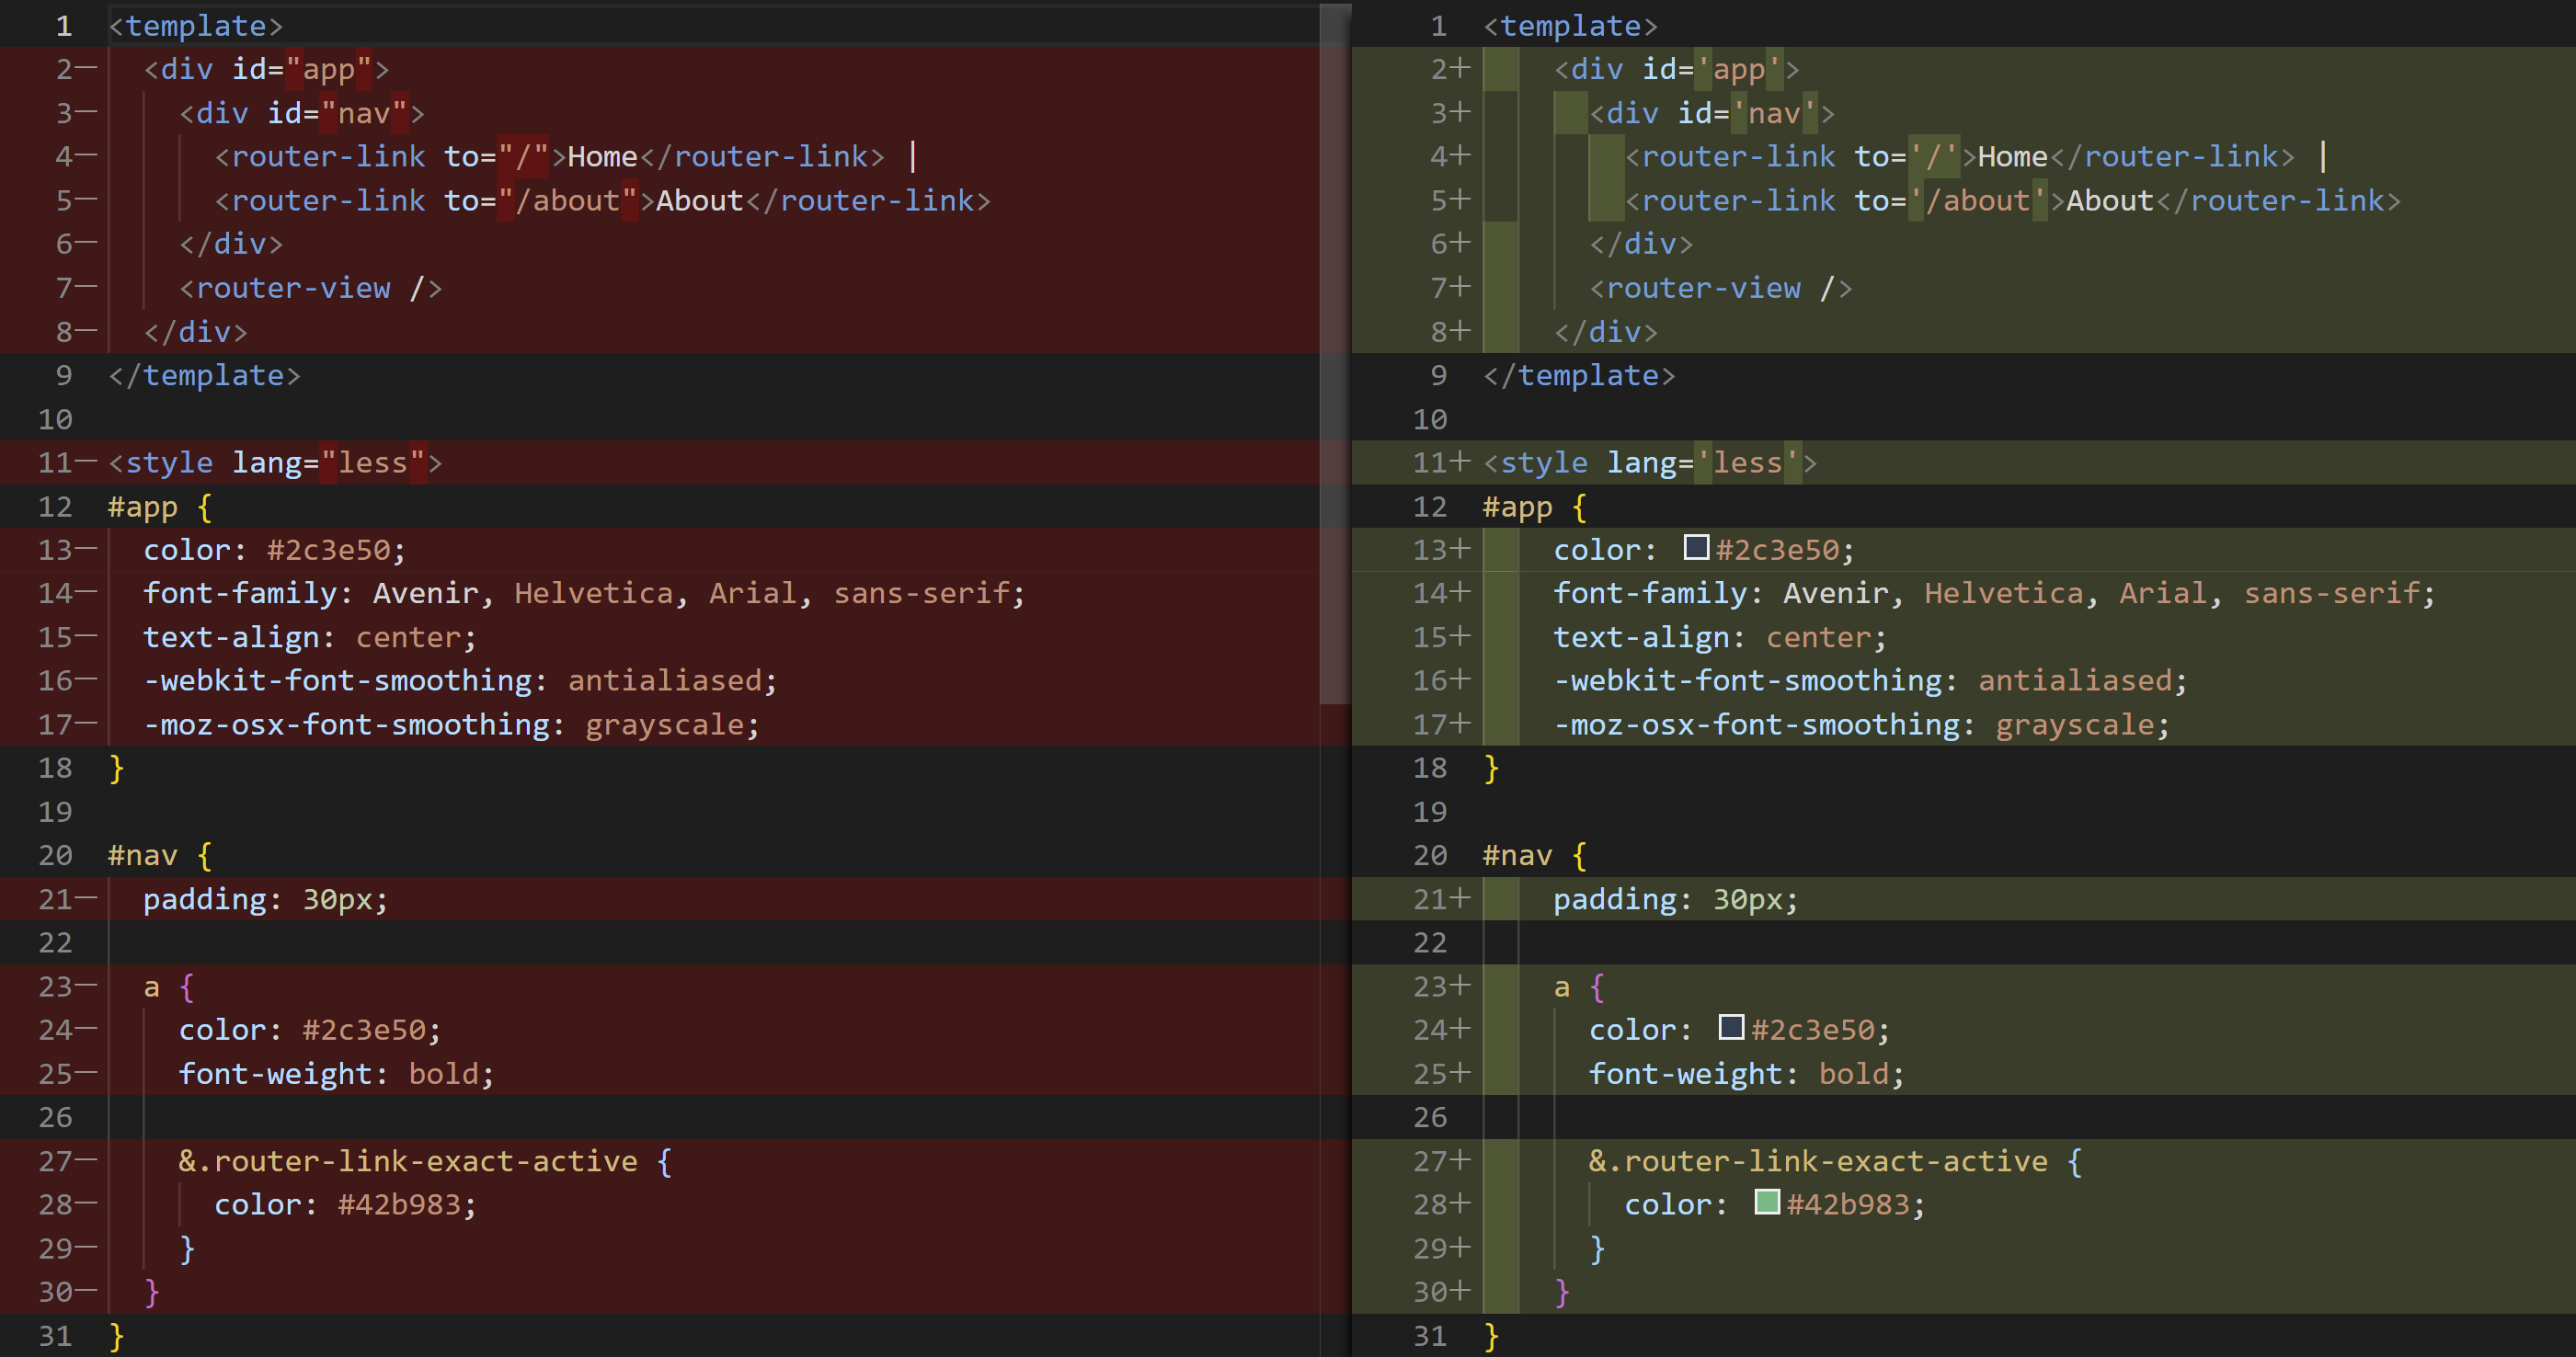


### 统一代码风格

ESLint 检查代码规则，Prettier 统一格式。原课把格式规则接入 ESLint，执行检查时也能修正格式。

在项目根目录安装相关开发依赖：


```bash
pnpm i -D eslint prettier eslint-plugin-vue @vue/eslint-config-prettier @vue/eslint-config-typescript @rushstack/eslint-patch @vue/tsconfig
```

新建或合并根目录的 `.eslintrc.cjs`：


```javascript
/* eslint-env node */
require('@rushstack/eslint-patch/modern-module-resolution')

module.exports = {
  root: true,
  extends: [
    'plugin:vue/vue3-essential',
    'eslint:recommended',
    '@vue/eslint-config-typescript',
    '@vue/eslint-config-prettier',
  ],
  // 小程序全局变量
  globals: {
    uni: true,
    wx: true,
    WechatMiniprogram: true,
    getCurrentPages: true,
    getApp: true,
    UniApp: true,
    UniHelper: true,
    App: true,
    Page: true,
    Component: true,
    AnyObject: true,
  },
  parserOptions: {
    ecmaVersion: 'latest',
  },
  rules: {
    'prettier/prettier': [
      'warn',
      {
        singleQuote: true,
        semi: false,
        printWidth: 100,
        trailingComma: 'all',
        endOfLine: 'auto',
      },
    ],
    'vue/multi-word-component-names': ['off'],
    'vue/no-setup-props-destructure': ['off'],
    'vue/no-deprecated-html-element-is': ['off'],
    '@typescript-eslint/no-unused-vars': ['off'],
  },
}
```

| 配置 | 用途 |
| --- | --- |
| `extends` | 组合 Vue 3、ESLint、TypeScript 和 Prettier 的规则 |
| `globals` | 声明 `uni`、`wx` 等平台提供的全局对象，避免误报未定义 |
| `singleQuote: true` | 使用单引号 |
| `semi: false` | 省略语句末尾分号 |
| `printWidth: 100` | 以 100 字符作为格式化换行参考 |
| `trailingComma: 'all'` | 在可使用尾逗号的位置保留尾逗号 |
| `endOfLine: 'auto'` | 按文件已有换行风格处理 |
| `rules` 中的 `off` | 按课程需要关闭对应规则 |

这是原课使用的 `.eslintrc.cjs` 时代配置。跟做时沿用模板已有依赖与版本；新版 ESLint、Vue 配置包的规则和配置方式可能变化，不应把不同代的配置直接混用。


### 配置检查命令

在根目录的 `package.json` 中把检查命令合并到现有 `scripts`：

> **原稿修正**：讲义写的是 `"script"`，实际字段应为 `"scripts"`。保留模板里的其他脚本。


```json
{
  "scripts": {
    "lint": "eslint . --ext .vue,.js,.ts --fix --ignore-path .gitignore"
  }
}
```

在项目根目录执行：


```bash
pnpm lint
```

`--ext` 指定检查 Vue、JavaScript 和 TypeScript 文件，`--fix` 自动修复可修复的问题，`--ignore-path .gitignore` 读取项目的忽略规则。

完成后应看到格式问题被统一；无法自动修复的检查错误，需要根据终端提示定位修改。


### Git 工作流规范

格式检查也要放进提交流程。Husky 提供 Git 钩子，lint-staged 只处理已经放进暂存区、准备提交的文件。

**1. 安装并初始化 Husky**

在项目根目录执行下面一种方式即可，二选一：

使用 pnpm：


```bash
pnpm dlx husky-init
```

使用 npx：


```bash
npx husky-init
```

这是讲义中的 `husky-init` 工作流，初始化会生成 `.husky` 目录及提交钩子。项目应已经是 Git 仓库；沿用模板已有版本，不要重复覆盖已配置的钩子。

**2. 安装 lint-staged**


```bash
pnpm i -D lint-staged
```

**3. 合并 package.json 配置**

原稿给出了 `lint-staged` 匹配规则，并在钩子中调用 `npm run lint-staged`，但省略了同名脚本。下面补齐该脚本，同时使用正确的 `scripts` 字段：


```json
{
  "scripts": {
    "lint": "eslint . --ext .vue,.js,.ts --fix --ignore-path .gitignore",
    "lint-staged": "lint-staged"
  },
  "lint-staged": {
    "*.{vue,ts,js}": [
      "eslint --fix"
    ]
  }
}
```

`scripts.lint-staged` 指定如何启动工具，顶层的 `lint-staged` 指定工具检查哪些文件、对它们执行什么命令。两个字段同名，但职责不同。

**4. 修改提交钩子**

在 `.husky/pre-commit` 中保留初始化生成的脚本头，把原来的测试命令改成 lint-staged 命令。原稿使用网页高亮标记表示删除、新增；这里写成标准 diff：


```diff
-npm test
+npm run lint-staged
```

提交时的顺序是：Git 触发 `pre-commit` → Husky 执行钩子 → 启动 lint-staged → 对暂存区匹配文件执行 `eslint --fix`。检查失败时，该次提交会被阻止。

**跟做检查**：在练习项目中修改并暂存一个 Vue 或 TypeScript 文件，提交时应看到 lint-staged 的检查过程。手动运行 `pnpm lint` 是整个项目检查，提交钩子执行的是暂存文件检查。


## 第 1 天完成检查

按本篇对应步骤检查项目：

- [ ] 已取得课程模板，真机预览所需的 AppID 已写入 `manifest.json`。
- [ ] uni-ui 的 `easycom` 规则已配置，类型声明已加入 `tsconfig.json`。
- [ ] Pinia 插件已注册，会员 Store 使用 `uni.setStorageSync` / `uni.getStorageSync` 持久化。
- [ ] 请求与上传拦截器已注册，基础地址、超时、来源标识和 Token 处理完整。
- [ ] `http<T>` 返回 Promise，并区分 2xx、401、其他错误、网络错误。
- [ ] `pnpm lint` 能执行，提交钩子能调用 lint-staged。
- [ ] `package.json` 使用 `scripts`，且钩子调用的脚本确实存在。

本天完成的是商城的公共基础能力。后续页面通过统一的组件、Store 和请求函数开展业务开发。
